In [12]:
import random
import sys
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

In [13]:
try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
FIGURES_DIR = ROOT / "figures"
NAMES_URL = "https://raw.githubusercontent.com/karpathy/makemore/master/names.txt"

In [14]:
def load_text(path: Path, url: str) -> str:
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        print(f"téléchargement de {url}")
        urllib.request.urlretrieve(url, path)
    return path.read_text(encoding="utf-8")

## 1. Le jeu de données

Même vocabulaire qu'au script 02 : 26 lettres et `.`. Le contexte passe à
**3 caractères** (`block_size = 3`). Un prénom de 4 lettres donne 5
exemples ; le contexte de départ est rempli de `.`.

In [15]:
words = load_text(DATA_DIR / "names.txt", NAMES_URL).splitlines()
chars = sorted(set("".join(words)))
stoi = {ch: i + 1 for i, ch in enumerate(chars)}
stoi["."] = 0
itos = {i: ch for ch, i in stoi.items()}
vocab_size = len(stoi)

In [ ]:
block_size = 3


def build_dataset(words_: list[str], verbose: bool = False) -> tuple[torch.Tensor, torch.Tensor]:
    """Transforme des prénoms en couples (contexte, caractère suivant).

    Args:
        words_: Prénoms à découper.
        verbose: Affiche les exemples produits (à réserver à quelques prénoms).

    Returns:
        `X` de forme `(N, block_size)` et `Y` de forme `(N,)`, en indices.
    """
    X, Y = [], []
    for w in words_:
        context = [0] * block_size
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            if verbose:
                print(f"  {''.join(itos[i] for i in context)} → {ch}")
            context = context[1:] + [ix]
    return torch.tensor(X), torch.tensor(Y)


build_dataset(["emmal"], verbose=True)


  ... → e
  ..e → m
  .em → m
  emm → a
  mma → l
  mal → .


(tensor([[ 0,  0,  0],
         [ 0,  0,  5],
         [ 0,  5, 13],
         [ 5, 13, 13],
         [13, 13,  1],
         [13,  1, 12]]),
 tensor([ 5, 13, 13,  1, 12,  0]))

On découpe les prénoms en **80 / 10 / 10** : entraînement, validation (pour
régler), test (une seule fois, à la fin). Même discipline qu'en séance 1.

In [17]:
random.seed(42)
random.shuffle(words)
n1, n2 = int(0.8 * len(words)), int(0.9 * len(words))
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])
print(f"train {tuple(Xtr.shape)}   val {tuple(Xdev.shape)}   test {tuple(Xte.shape)}")

train (182625, 3)   val (22655, 3)   test (22866, 3)


## 2. La table d'embeddings

`C` a une ligne par caractère. On commence avec des vecteurs de **dimension
2** : trop petit pour bien prédire, mais on pourra les **dessiner**. Au
départ ils sont aléatoires ; c'est l'entraînement qui va les placer.

Le script 01 l'a montré : `one_hot(ix) @ C == C[ix]`. PyTorch sait indexer avec un tenseur entier de n'importe quelle forme : `C[X]` remplace chaque
indice de `X` par sa ligne de `C`, d'un coup.

In [18]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, 2), generator=g)

print(f"C       : {tuple(C.shape)}")
print(f"C[5]    : {C[5]}")
print(f"one-hot : {F.one_hot(torch.tensor(5), num_classes=vocab_size).float() @ C}")
emb = C[Xtr]
print(f"C[Xtr]  : {tuple(emb.shape)}   (exemples, contexte, dimension)")

C       : (27, 2)
C[5]    : tensor([-0.4713,  0.7868])
one-hot : tensor([-0.4713,  0.7868])
C[Xtr]  : (182625, 3, 2)   (exemples, contexte, dimension)


## 3. Le réseau

Le MLP de Bengio, à une couche cachée :

1. aller chercher les 3 embeddings du contexte : `(B, 3, 2)` ;
2. les **mettre bout à bout** : `(B, 6)`. `view` le fait sans copier la
   mémoire ;
3. couche cachée `tanh` de 100 neurones ;
4. couche de sortie : 27 logits, un par caractère possible ;
5. `cross_entropy` : softmax puis NLL, la loss du script 02.

Le nombre de paramètres **ne dépend plus** de `27^block_size` : ajouter un
caractère de contexte ajoute seulement quelques entrées à la première couche.

On l'écrit comme un `nn.Module`, comme les réseaux de la séance 1, mais sans
couche toute faite : chaque paramètre est un `nn.Parameter` créé à la main.
`self.C` est la table de la section 2 : même graine, même premier tirage.

In [21]:
class BengioMLP(nn.Module):
    """MLP de Bengio et al. (2003) : embeddings, couche cachée tanh, sortie."""

    def __init__(self, emb_dim: int, hidden: int, seed: int = 2147483647):
        """Crée les paramètres : embeddings, couche cachée, sortie.

        Args:
            emb_dim: Dimension des embeddings.
            hidden: Nombre de neurones de la couche cachée.
            seed: Graine du générateur, pour des initialisations reproductibles.
        """
        super().__init__()
        g_ = torch.Generator().manual_seed(seed)
        self.C = nn.Parameter(torch.randn((vocab_size, emb_dim), generator=g_))
        self.W1 = nn.Parameter(torch.randn((block_size * emb_dim, hidden), generator=g_))
        self.b1 = nn.Parameter(torch.randn(hidden, generator=g_))
        self.W2 = nn.Parameter(torch.randn((hidden, vocab_size), generator=g_))
        self.b2 = nn.Parameter(torch.randn(vocab_size, generator=g_))

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        """Passe avant : renvoie les logits du caractère suivant.

        Args:
            X: Contextes, de forme `(B, block_size)`.

        Returns:
            Les logits, de forme `(B, vocab_size)`.
        """
        emb_ = self.C[X]  # (B, block_size, emb_dim)
        h = torch.tanh(emb_.view(emb_.shape[0], -1) @ self.W1 + self.b1)
        return h @ self.W2 + self.b2


model = BengioMLP(emb_dim=2, hidden=100)
print(f"paramètres : {sum(p.nelement() for p in model.parameters()):,}")
print(f"model.C est la table C de la section 2 : {torch.equal(model.C.detach(), C)}")

paramètres : 3,481
model.C est la table C de la section 2 : True


## 4. Entraîner par mini-lots

Text(0, 0.5, 'log10(loss) du mini-batch')

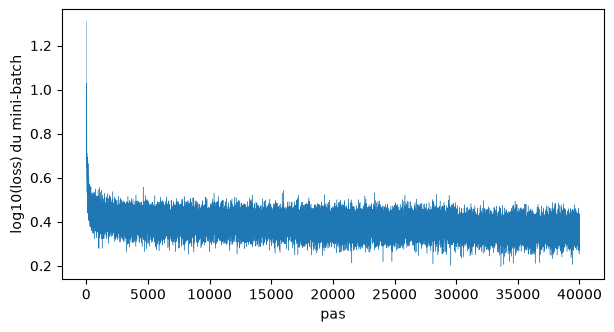

In [22]:
@torch.no_grad()
def evaluate(model_: nn.Module, X: torch.Tensor, Y: torch.Tensor) -> float:
    """Loss moyenne sur un jeu complet, sans calcul de gradient."""
    return F.cross_entropy(model_(X), Y).item()


def train(model_: nn.Module, steps: int, batch_size: int = 32, seed: int = 1337) -> list[float]:
    """Entraîne le MLP par descente de gradient sur mini-lots.

    Args:
        model_: Modèle à entraîner, modifié sur place.
        steps: Nombre de pas de gradient.
        batch_size: Taille des mini-lots.
        seed: Graine du tirage des mini-lots.

    Returns:
        La loss de chaque pas (log10), pour tracer la courbe.
    """
    g_ = torch.Generator().manual_seed(seed)
    losses = []
    for step in range(steps):
        ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g_)
        loss = F.cross_entropy(model_(Xtr[ix]), Ytr[ix])
        for p in model_.parameters():
            p.grad = None
        loss.backward()
        lr = 0.1 if step < steps * 3 // 4 else 0.01
        for p in model_.parameters():
            p.data -= lr * p.grad
        losses.append(loss.log10().item())
    return losses

losses = train(model, steps=40_000)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(losses, lw=0.3)
ax.set_xlabel("pas")
ax.set_ylabel("log10(loss) du mini-batch")

La courbe est **bruitée** : chaque point est la loss de 32 exemples
seulement. On juge le modèle sur un jeu complet

## 5. Train, validation, et le bigramme à battre

In [23]:
print(f"loss train : {evaluate(model, Xtr, Ytr):.4f}")
print(f"loss val   : {evaluate(model, Xdev, Ydev):.4f}")
print("bigramme du script 02 : ≈ 2.45")

loss train : 2.3303
loss val   : 2.3333
bigramme du script 02 : ≈ 2.45


Avec des embeddings de dimension 2 seulement, le MLP bat déjà le bigramme,
et train et validation sont au même niveau : le modèle **ne récite pas**, il
généralise. C'est exactement ce que le comptage n'arrivait pas à faire au-delà
de 4 caractères de contexte.

## 6. Les embeddings en 2D

Personne n'a dit au réseau ce qu'est une voyelle. Regardons où il a rangé
les caractères.

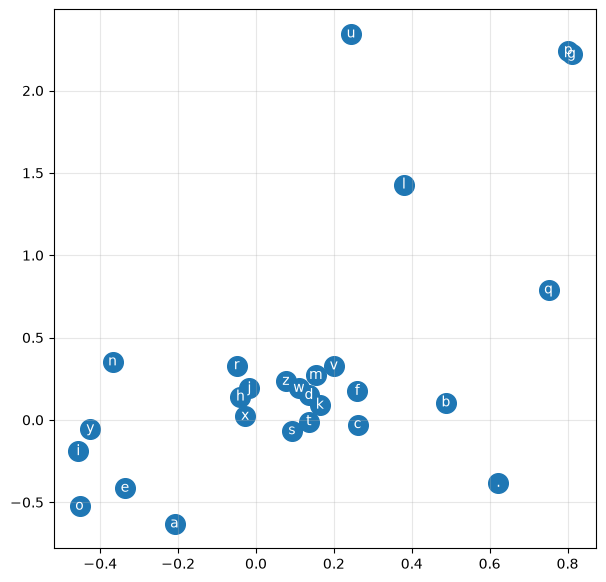

In [24]:
C_2d = model.C.detach()
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(C_2d[:, 0], C_2d[:, 1], s=200)
for i in range(vocab_size):
    ax.text(C_2d[i, 0].item(), C_2d[i, 1].item(), itos[i], ha="center", va="center", color="white")
ax.grid(alpha=0.3)

Les voyelles `a e i o` (et `y`) se regroupent d'un côté, la masse des
consonnes courantes au centre, et quelques caractères s'isolent : `.` joue un
rôle à part (début et fin), `q` est presque toujours suivi de `u`. Le réseau
a découvert ces catégories **parce qu'elles l'aident à prédire**. Des caractères qui se comportent pareil reçoivent des vecteurs
proches, et ce qu'il apprend sur l'un profite à l'autre.
(La disposition exacte change avec la seed ; les regroupements restent.)

## 7. Mesurer la proximité : la similarité cosinus

« Proche » demande une mesure. La distance euclidienne dépend de la
**longueur** des vecteurs ; or la longueur d'un embedding reflète souvent la
fréquence du token plutôt que son sens. On compare donc les **directions** :
le cosinus de l'angle entre deux vecteurs,

    cos(u, v) = (u · v) / (‖u‖ ‖v‖)

1 : même direction. 0 : orthogonaux, rien en commun. −1 : opposés. C'est la
mesure qu'utilisent la recherche sémantique et le RAG, sur des embeddings de
phrases entières au lieu de caractères.

In [25]:
def cosine(u: torch.Tensor, v: torch.Tensor) -> float:
    """Similarité cosinus entre deux vecteurs.

    Args:
        u: Premier vecteur.
        v: Second vecteur, de même dimension.

    Returns:
        Le cosinus de l'angle entre `u` et `v`, entre -1 et 1.
    """
    return (u @ v / (u.norm() * v.norm())).item()


C_2d = model.C.detach()
a, e, x = C_2d[stoi["a"]], C_2d[stoi["e"]], C_2d[stoi["x"]]
print(f"cos(a, e) = {cosine(a, e):+.3f}")
print(f"cos(a, x) = {cosine(a, x):+.3f}")
print(f"PyTorch   = {F.cosine_similarity(a, e, dim=0).item():+.3f}")

cos(a, e) = +0.935
cos(a, x) = -0.348
PyTorch   = +0.935


En dimension 2, le cosinus ne dit pas grand-chose : il n'y a que deux
directions possibles, et deux vecteurs pris au hasard sont souvent presque
alignés, dans un sens ou dans l'autre (|cos| > 0,7 une fois sur deux).
En grande dimension, c'est l'inverse : deux vecteurs au hasard sont presque
toujours quasi orthogonaux. Un cosinus élevé y devient alors un vrai signal,
et « orthogonal » veut dire « sans rapport ».

## 8. Des embeddings plus grands

Deuxième modèle : embeddings de dimension 10,
couche cachée de 200 neurones. On ne peut plus dessiner, mais on peut
calculer toutes les similarités d'un coup : on **normalise** chaque ligne de
`C`, et le produit `Cn @ Cn.T` donne la matrice 27 × 27 des cosinus.

In [26]:
model10 = BengioMLP(emb_dim=10, hidden=200)
train(model10, steps=80_000)
print(f"dim 10 — loss train : {evaluate(model10, Xtr, Ytr):.4f}   val : {evaluate(model10, Xdev, Ydev):.4f}")

C10 = model10.C.detach()
Cn = F.normalize(C10, dim=1)
similarity = Cn @ Cn.T


def neighbours(ch: str, k: int = 4) -> str:
    """Les `k` caractères dont l'embedding est le plus proche en cosinus."""
    sims = similarity[stoi[ch]].clone()
    sims[stoi[ch]] = -2.0  # on s'exclut soi-même
    top = sims.topk(k)
    return "  ".join(f"{itos[i.item()]} {s:+.2f}" for s, i in zip(top.values, top.indices))


for ch in ["a", "e", "b", "n", "q", "."]:
    print(f"voisins de {ch!r} : {neighbours(ch)}")

dim 10 — loss train : 2.1799   val : 2.2081
voisins de 'a' : y +0.51  g +0.51  b +0.45  m +0.45
voisins de 'e' : o +0.88  u +0.88  i +0.88  y +0.78
voisins de 'b' : d +0.92  p +0.82  f +0.80  g +0.78
voisins de 'n' : r +0.83  x +0.80  z +0.78  y +0.70
voisins de 'q' : . +0.51  k +0.47  l +0.19  c +0.13
voisins de '.' : k +0.78  c +0.52  q +0.51  l +0.13


### Pourquoi presque tous les cosinus sont positifs ?

Si les embeddings étaient répartis au hasard, la moitié des cosinus seraient
négatifs. Ici, plus de 8 paires sur 10 sont positives. La raison : les 27
vecteurs ne sont pas **centrés**. Ils partagent une partie commune, leur
**vecteur moyen**, qui les tire tous dans la même direction.

Pour le vérifier, on retire ce vecteur moyen à chaque embedding (on les
**centre**) et on recalcule les cosinus. On compare avec des vecteurs
aléatoires de même taille.

norme moyenne d'un embedding : 1.44
norme du vecteur moyen       : 0.76
embeddings entraînés   cos moyen +0.378   part > 0 : 84%
après centrage         cos moyen +0.011   part > 0 : 50%
vecteurs aléatoires    cos moyen +0.026   part > 0 : 52%


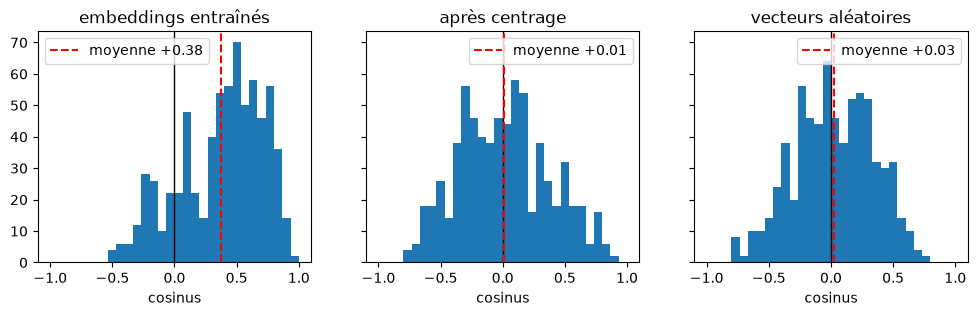

In [29]:
def pairwise_cosines(M: torch.Tensor) -> torch.Tensor:
    """Cosinus de toutes les paires de lignes distinctes de `M`."""
    Mn = F.normalize(M, dim=1)
    S = Mn @ Mn.T
    return S[~torch.eye(M.shape[0], dtype=torch.bool)]


mean_vec = C10.mean(dim=0)
print(f"norme moyenne d'un embedding : {C10.norm(dim=1).mean():.2f}")
print(f"norme du vecteur moyen       : {mean_vec.norm():.2f}")

g_rand = torch.Generator().manual_seed(0)
cases = {
    "embeddings entraînés": pairwise_cosines(C10),
    "après centrage": pairwise_cosines(C10 - mean_vec),
    "vecteurs aléatoires": pairwise_cosines(torch.randn(C10.shape, generator=g_rand)),
}
for name, cos in cases.items():
    print(f"{name:22} cos moyen {cos.mean():+.3f}   part > 0 : {(cos > 0).float().mean():.0%}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, (name, cos) in zip(axes, cases.items()):
    ax.hist(cos, bins=30, range=(-1, 1))
    ax.axvline(0, color="black", lw=1)
    ax.axvline(cos.mean(), color="red", ls="--", label=f"moyenne {cos.mean():+.2f}")
    ax.set_title(name)
    ax.set_xlabel("cosinus")
    ax.legend()
plt.show()

Une fois centrés, les cosinus retrouvent la répartition du hasard, autour de
0. Le décalage venait donc d'**une seule direction**, partagée par tous les
caractères. Elle n'aide pas à les distinguer, et rien dans l'entraînement ne
pousse à la supprimer.

Conséquence pour la lecture : un cosinus de +0,5 n'est pas « assez proche »
dans l'absolu, puisque la moyenne est déjà autour de +0,4. On compare des
similarités **entre elles** plutôt qu'à zéro. Les grands modèles ont le même
travers : leurs embeddings sont rarement centrés (on parle d'**anisotropie**).

### Solution ? Similarité absolue ou relative ?

Il y a deux façons de lire un cosinus :

- **en absolu** : on compare la valeur à une échelle fixe. Proche de 1, les
  vecteurs se ressemblent ; proche de 0, ils n'ont rien en commun ; proche de
  −1, ils sont opposés. Par exemple « cos(a, e) = 0,5, donc a et e se
  ressemblent moyennement » ;
- **en relatif** : on compare les cosinus **entre eux**. On ne se demande plus
  si 0,5 est élevé, mais si c'est plus ou moins que les autres. Par exemple
  « e est plus proche de o que de b ».

La lecture absolue suppose que 0 veut vraiment dire « sans rapport ». Ce n'est
vrai que si les vecteurs sont centrés. Ici, ils partagent une direction
commune : tous les cosinus sont décalés vers le haut, et le zéro de l'échelle
ne veut plus rien dire. Un cosinus de +0,5 est à peine au-dessus de la
moyenne (+0,4).

La lecture relative, elle, ne dépend pas de ce décalage : il s'ajoute à toutes
les paires, et l'ordre ne change pas. C'est pour ça que `neighbours` renvoie
les **k plus proches** (`topk`) plutôt que tous les caractères au-dessus d'un
seuil. C'est aussi ce que fait la recherche sémantique d'un RAG : elle ne
garde pas les documents « similaires à plus de 0,8 », elle garde les **k
meilleurs**.

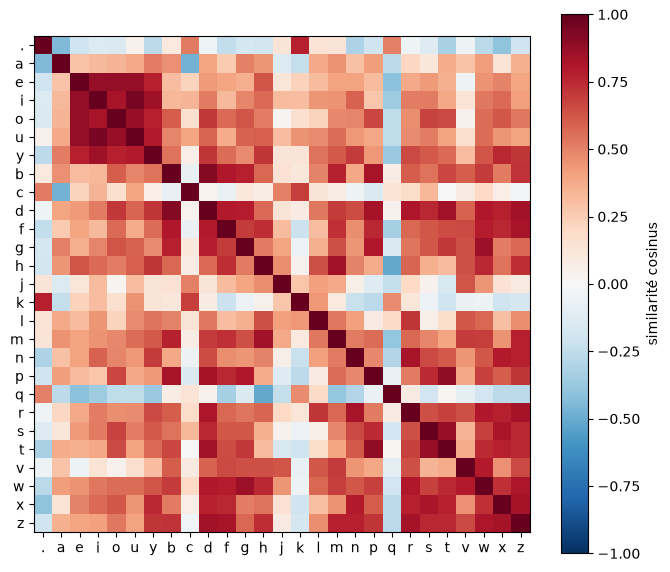

In [27]:
order = [stoi[c] for c in ".aeiouy" + "bcdfghjklmnpqrstvwxz"]
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(similarity[order][:, order], cmap="RdBu_r", vmin=-1, vmax=1)
labels = [itos[i] for i in order]
ax.set_xticks(range(vocab_size), labels)
ax.set_yticks(range(vocab_size), labels)
fig.colorbar(im, ax=ax, label="similarité cosinus")

La matrice est rangée voyelles d'abord : le bloc `e i o u y` ressort
nettement. `a` s'en écarte : avec `n`, c'est la lettre finale la plus
fréquente des prénoms (script 02), elle ne se comporte pas comme les autres
voyelles, et le réseau l'a rangée à part. `q` n'est proche de presque rien. Les voisins de chaque caractère se lisent comme une **classification apprise** sans aucune
étiquette, seulement parce qu'elle aide à prédire la suite.

C'est tout le principe des embeddings, qu'on retrouvera à toutes les
échelles : pour des mots (word2vec), pour des phrases (le RAG),
pour des images et du texte dans un même espace (CLIP).

## 9. Générer

Même boucle qu'au script 02 : on part d'un contexte de `.`, on tire, on
décale le contexte. Seul le calcul de la distribution a changé.

In [28]:
with torch.no_grad():
    for _ in range(10):
        out, context = [], [0] * block_size
        while True:
            probs = F.softmax(model10(torch.tensor([context])), dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=g).item()
            context = context[1:] + [ix]
            if ix == 0:
                break
            out.append(itos[ix])
        print("".join(out))

kure
azerimarah
rayl
meneraelynna
jaconce
camsa
leri
mehl
kamarlee
asra


Les prénoms sont nettement plus crédibles qu'avec le bigramme. Mais le
contexte reste **fixe** : 3 caractères, jamais plus. Pour un texte, il faut
pouvoir regarder beaucoup plus loin, sans que la première couche grossisse
avec chaque caractère ajouté. Première idée historique : le réseau récurrent.